# Binary Classification for Bank Marketing

**Goal :** Predict whether a client will subscribe to a term deposit (Yes/No) after a marketing campaign.

**Dataset :** UCI Bank Marketing Dataset ( balanced version from Kaggle)

---


## 1. Imports & Configuration

In [1]:
# Standard libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Scikit-learn: preprocessing & model selection 
from sklearn.model_selection import train_test_split, cross_validate, KFold, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc
)

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import xgboost as xgb

# Imbalanced-learn (SMOTE for oversampling) 
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline

# Global style settings 
SEED = 42                       # for reproducibility
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "DejaVu Sans"

PALETTE = {
    "yes": "#2ecc71",           # green  → subscribed
    "no":  "#e74c3c",           # red    → did not subscribe
    "main": "#3498db",          # blue   → generic
}

print("All libraries imported successfully.")
print(f"Random seed set to: {SEED}")


All libraries imported successfully.
Random seed set to: 42


## 2. Load Dataset

In [2]:

df = pd.read_csv("bank.csv")

# Rename the target column to something clearer
df.rename(columns={"deposit": "term_deposit"}, inplace=True)

print(f"Dataset loaded successfully!")
print(f"Rows : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")
print(f"\n  Column names:")
for col in df.columns:
    print(f"     • {col}")


Dataset loaded successfully!
Rows : 11162
Columns : 17

  Column names:
     • age
     • job
     • marital
     • education
     • default
     • balance
     • housing
     • loan
     • contact
     • day
     • month
     • duration
     • campaign
     • pdays
     • previous
     • poutcome
     • term_deposit


## 3. Initial Data Exploration

In [3]:
#data overview
print("=" * 60)
print("FIRST 5 ROWS")
print("=" * 60)
display(df.head())

print("\n" + "=" * 60)
print("COLUMN DATA TYPES & NON-NULL COUNTS")
print("=" * 60)
df.info()

print("\n" + "=" * 60)
print("STATISTICAL SUMMARY (numeric columns)")
print("=" * 60)
display(df.describe().round(2))


FIRST 5 ROWS


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,term_deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes



COLUMN DATA TYPES & NON-NULL COUNTS
<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   age           11162 non-null  int64
 1   job           11162 non-null  str  
 2   marital       11162 non-null  str  
 3   education     11162 non-null  str  
 4   default       11162 non-null  str  
 5   balance       11162 non-null  int64
 6   housing       11162 non-null  str  
 7   loan          11162 non-null  str  
 8   contact       11162 non-null  str  
 9   day           11162 non-null  int64
 10  month         11162 non-null  str  
 11  duration      11162 non-null  int64
 12  campaign      11162 non-null  int64
 13  pdays         11162 non-null  int64
 14  previous      11162 non-null  int64
 15  poutcome      11162 non-null  str  
 16  term_deposit  11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB

STATISTICAL SUMMARY (numeric columns)


,age,balance,day,duration,campaign,pdays,previous
count,11162.00,11162.00,11162.00,11162.00,11162.00,11162.00,11162.00
mean,41.23,1528.54,15.66,371.99,2.51,51.33,0.83
std,11.91,3225.41,8.42,347.13,2.72,108.76,2.29
min,18.00,-6847.00,1.00,2.00,1.00,-1.00,0.00
25%,32.00,122.00,8.00,138.00,1.00,-1.00,0.00
50%,39.00,550.00,15.00,255.00,2.00,-1.00,0.00
75%,49.00,1708.00,22.00,496.00,3.00,20.75,1.00
max,95.00,81204.00,31.00,3881.00,63.00,854.00,58.00


In [4]:
# Checking mapissing values 
missing = df.isnull().sum()
print("=" * 40)
print("MISSING VALUES PER COLUMN")
print("=" * 40)
if missing.sum() == 0:
    print("No missing values found! The dataset is clean.")
else:
    print(missing[missing > 0])


MISSING VALUES PER COLUMN
No missing values found! The dataset is clean.


In [5]:
# Target variable distribution 
counts = df["term_deposit"].value_counts()
pct    = df["term_deposit"].value_counts(normalize=True) * 100

print("=" * 40)
print("TARGET VARIABLE: term_deposit")
print("=" * 40)
for label in counts.index:
    print(f"  {label:>3}  →  {counts[label]:>5} clients  ({pct[label]:.1f}%)")
print()
print("ℹThe dataset is BALANCED (roughly 50/50) — no oversampling strictly")
print("needed, but we are keep SMOTE in the pipeline later as good practice.")


TARGET VARIABLE: term_deposit
   no  →   5873 clients  (52.6%)
  yes  →   5289 clients  (47.4%)

ℹThe dataset is BALANCED (roughly 50/50) — no oversampling strictly
needed, but we are keep SMOTE in the pipeline later as good practice.


## 4. Data Cleaning

In [6]:
# Separate numeric and categorical columns
num_cols = df.select_dtypes(exclude="object").columns.tolist()
cat_cols = df.select_dtypes(include="object").columns.tolist()
cat_cols.remove("term_deposit")  # target is not a feature

print(f"Numeric  features ({len(num_cols)}): {num_cols}")
print(f"Categorical features ({len(cat_cols)}): {cat_cols}")

# Drop 'pdays' — it's redundant with 'previous' (highly correlated ) 
if "pdays" in num_cols:
    df.drop("pdays", axis=1, inplace=True)
    num_cols.remove("pdays")
    print("\n Dropped 'pdays' (redundant with 'previous').")

print("\n Cleaning complete.")


Numeric  features (7): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical features (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

 Dropped 'pdays' (redundant with 'previous').

 Cleaning complete.


## 5. Exploratory Data Analysis (EDA)

we visualise the data to understand **which client characteristics are linked to subscribing**.


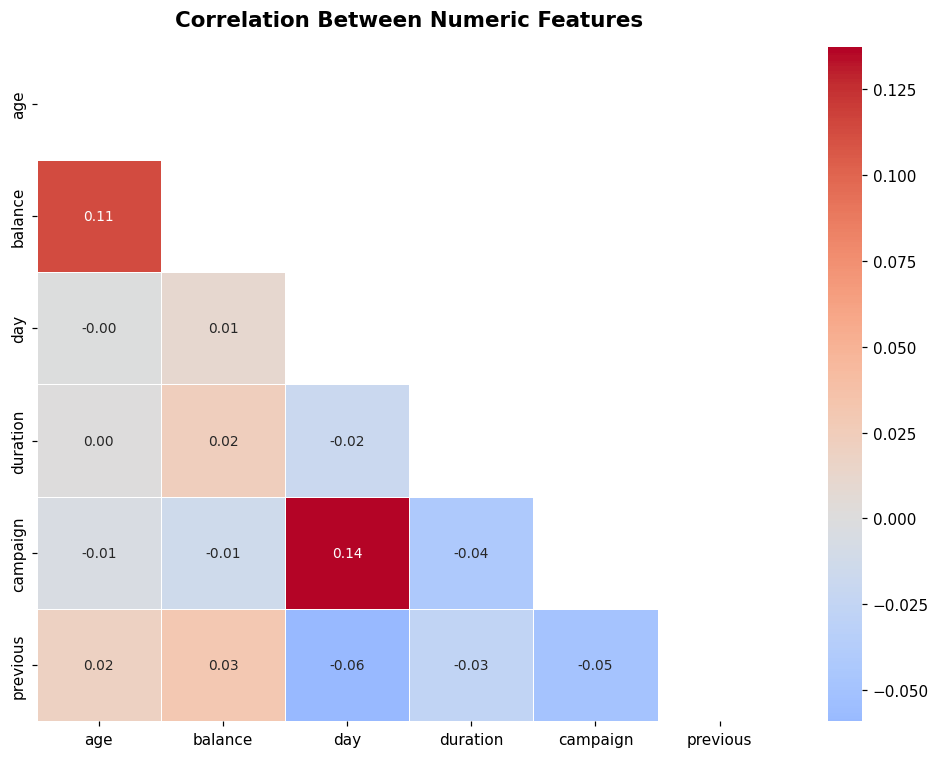

Insight: Values close to +1 or -1 indicate strong correlation.
Strongly correlated features carry duplicate information 


In [7]:
# Correlation heatmap (numeric features)
fig, ax = plt.subplots(figsize=(9, 7))

corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))   # to show only lower triangle

sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f",
    cmap="coolwarm", center=0, linewidths=0.5,
    annot_kws={"size": 9}, ax=ax
)
ax.set_title("Correlation Between Numeric Features", fontsize=14, fontweight="bold", pad=14)
plt.tight_layout()
plt.show()

print("Insight: Values close to +1 or -1 indicate strong correlation.")
print("Strongly correlated features carry duplicate information ")


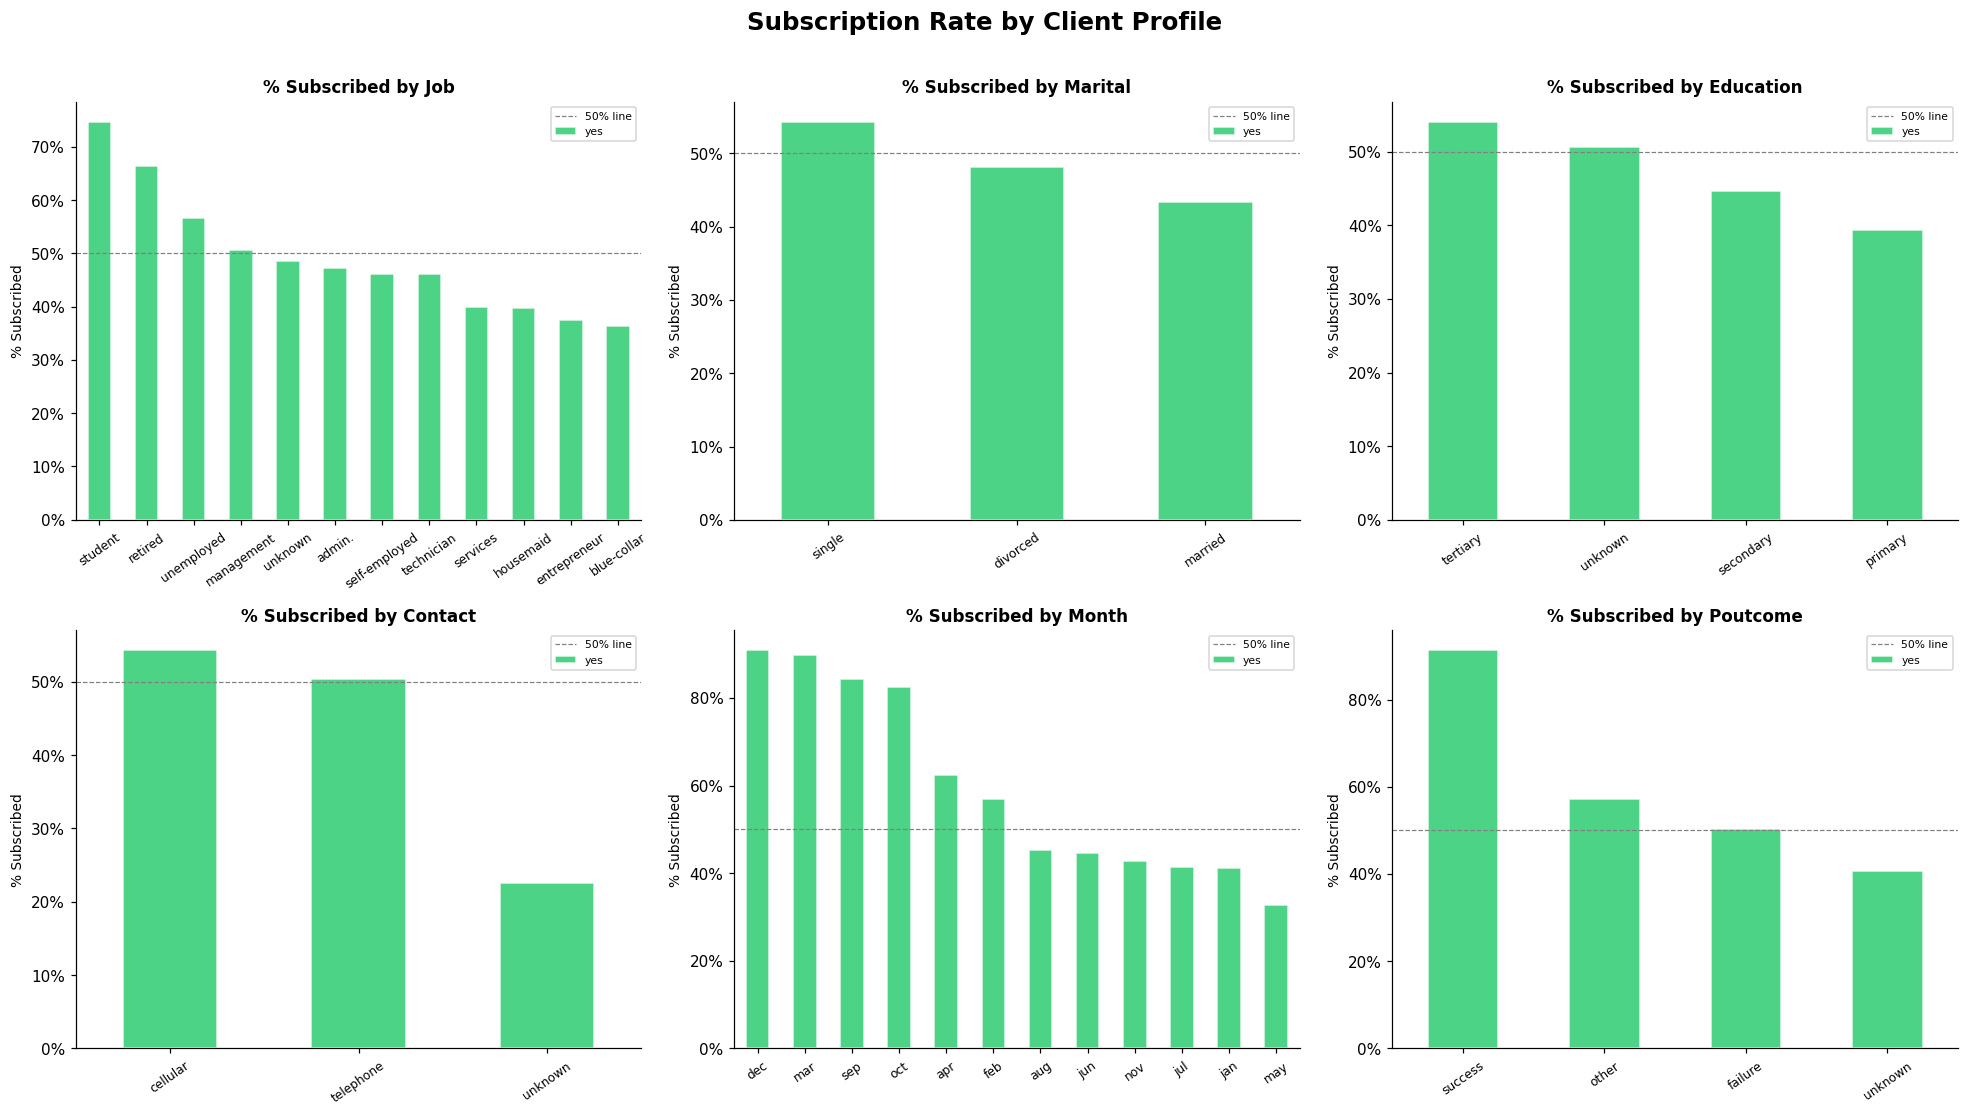

Insight: 'poutcome' (previous campaign outcome) is a strong predictor.
Clients previously contacted with success are much more likely to subscribe.


In [8]:
# Subscription rate by categorical variables 
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Subscription Rate by Client Profile", fontsize=16, fontweight="bold", y=1.01)

cat_features_to_plot = ["job", "marital", "education", "contact", "month", "poutcome"]

for ax, col in zip(axes.flat, cat_features_to_plot):
    # count yes/no per category
    ct = df.groupby(col)["term_deposit"].value_counts(normalize=True).unstack().fillna(0) * 100
    ct = ct.sort_values("yes", ascending=False)

    ct["yes"].plot(
        kind="bar", ax=ax,
        color=PALETTE["yes"], alpha=0.85, edgecolor="white"
    )
    ax.set_title(f"% Subscribed by {col.capitalize()}", fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("% Subscribed", fontsize=9)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.tick_params(axis="x", rotation=35, labelsize=8)
    ax.axhline(50, color="gray", linestyle="--", linewidth=0.8, label="50% line")
    ax.legend(fontsize=7)
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

print("Insight: 'poutcome' (previous campaign outcome) is a strong predictor.")
print("Clients previously contacted with success are much more likely to subscribe.")


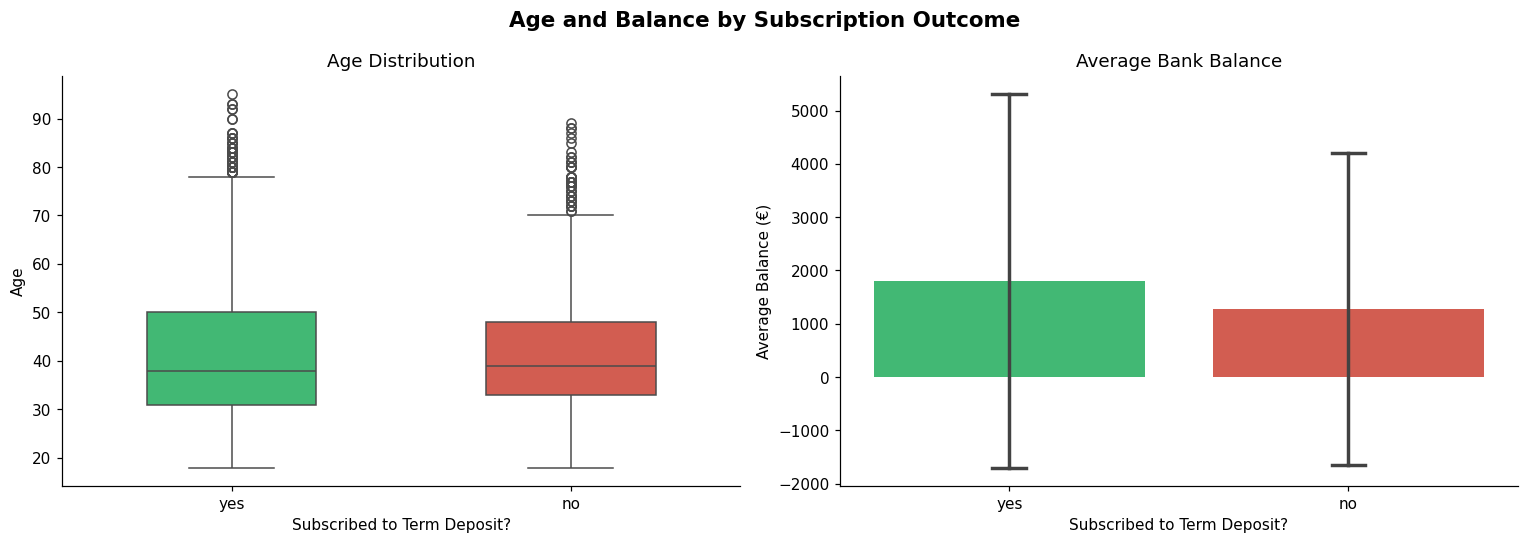

Insight: Clients who subscribed tend to have a slightly higher average balance.


In [9]:
# Age & Balance distributions by outcome 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Age and Balance by Subscription Outcome", fontsize=14, fontweight="bold")

# Age boxplot
sns.boxplot(
    data=df, x="term_deposit", y="age",
    palette={"yes": PALETTE["yes"], "no": PALETTE["no"]},
    ax=axes[0], width=0.5
)
axes[0].set_title("Age Distribution", fontsize=12)
axes[0].set_xlabel("Subscribed to Term Deposit?", fontsize=10)
axes[0].set_ylabel("Age", fontsize=10)
sns.despine(ax=axes[0])

# Balance barplot
sns.barplot(
    data=df, x="term_deposit", y="balance",
    palette={"yes": PALETTE["yes"], "no": PALETTE["no"]},
    ax=axes[1], errorbar="sd", capsize=0.1
)
axes[1].set_title("Average Bank Balance", fontsize=12)
axes[1].set_xlabel("Subscribed to Term Deposit?", fontsize=10)
axes[1].set_ylabel("Average Balance (€)", fontsize=10)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()

print("Insight: Clients who subscribed tend to have a slightly higher average balance.")


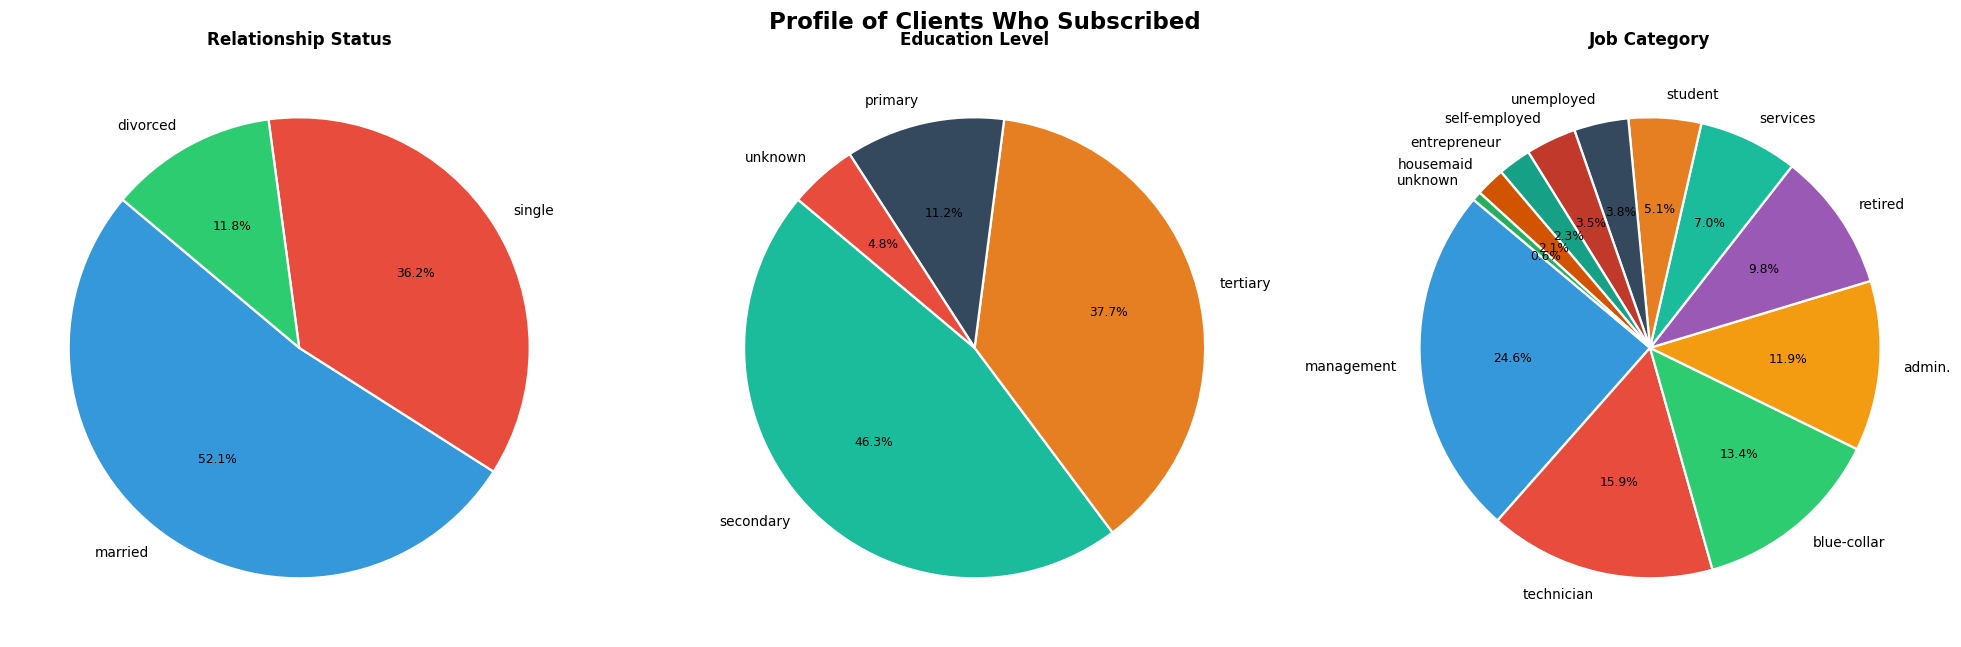

In [10]:
# Client profile pie charts ────────────────────────────────────────────
subscribers = df[df["term_deposit"] == "yes"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Profile of Clients Who Subscribed", fontsize=15, fontweight="bold")

pie_configs = [
    ("marital",   "Relationship Status"),
    ("education", "Education Level"),
    ("job",       "Job Category"),
]

colors_set = [
    ["#3498db","#e74c3c","#2ecc71","#f39c12","#9b59b6"],
    ["#1abc9c","#e67e22","#34495e","#e74c3c"],
    ["#3498db","#e74c3c","#2ecc71","#f39c12","#9b59b6","#1abc9c","#e67e22","#34495e","#c0392b","#16a085","#d35400","#27ae60"],
]

for ax, (col, title), colors in zip(axes, pie_configs, colors_set):
    sizes = subscribers[col].value_counts()
    wedges, texts, autotexts = ax.pie(
        sizes, labels=sizes.index, autopct="%1.1f%%",
        colors=colors[:len(sizes)], startangle=140,
        wedgeprops={"edgecolor": "white", "linewidth": 1.5},
        textprops={"fontsize": 9}
    )
    for at in autotexts:
        at.set_fontsize(8)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=10)

plt.tight_layout()
plt.show()


## 6. Encoding & Scaling

- **Ordinal Encoding** converts categorical columns into a single integer column (e.g., job → 0,1,2…). This keeps **one column per feature**, which means feature importance charts show the original feature names — perfect for Streamlit dropdowns.
- **Min-Max Scaling** rescales numeric columns to the range [0, 1] so no feature dominates.


In [11]:
# Encode the target variable
le = LabelEncoder()
df["target"] = le.fit_transform(df["term_deposit"])   # yes=1, no=0
print(f"Target encoding: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Ordinal encode categorical features (keeps each feature as ONE column)
# This is ideal for tree-based models (XGBoost, RF, Decision Tree) and
# means feature importance will show the original column names, not dummies.
oe = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
cat_encoded = oe.fit_transform(df[cat_cols])
cat_encoded_df = pd.DataFrame(cat_encoded, columns=cat_cols)   # same column names!

# Combine numeric + encoded categorical
X_raw = pd.concat([df[num_cols].reset_index(drop=True), cat_encoded_df.reset_index(drop=True)], axis=1)
y     = df["target"].values

print(f"\nFeature matrix shape: {X_raw.shape}")
print(f"Target vector shape  : {y.shape}")
print(f"Positive class (yes) : {y.sum()} ({y.mean()*100:.1f}%)")
print(f"\nFeature columns (one per original feature):")
print(list(X_raw.columns))


Target encoding: {'no': np.int64(0), 'yes': np.int64(1)}

Feature matrix shape: (11162, 15)
Target vector shape  : (11162,)
Positive class (yes) : 5289 (47.4%)

Feature columns (one per original feature):
['age', 'balance', 'day', 'duration', 'campaign', 'previous', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [12]:
# Train / Test split (80% train, 20% test, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=SEED
)

# Scale numeric features 
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Train set : {X_train_scaled.shape[0]} samples")
print(f"Test set  : {X_test_scaled.shape[0]} samples")
print("\nImportant: we fitted teh scalet ONLY on training data to prevent data leakage")


Train set : 8929 samples
Test set  : 2233 samples

Important: we fitted teh scalet ONLY on training data to prevent data leakage


## 7. Model Training & Cross-Validation

We test **6 classifiers** using 5-fold cross-validation with SMOTE oversampling inside the pipeline.

**Why SMOTE?** Even though the dataset is balanced, SMOTE ensures each fold during cross-validation is balanced — a good habit.

**Why cross-validation?** It gives a more reliable performance estimate than a single train/test split.


In [13]:
# Define all classifiers 
classifiers = [
    ("Logistic Regression", LogisticRegression(random_state=SEED, max_iter=4000)),
    ("K-Nearest Neighbors", KNeighborsClassifier()),
    ("Decision Tree",       DecisionTreeClassifier(random_state=SEED)),
    ("Random Forest",       RandomForestClassifier(random_state=SEED, n_estimators=100)),
    ("SVM",                 SVC(random_state=SEED, probability=True)),
    ("XGBoost",             xgb.XGBClassifier(random_state=SEED, eval_metric="logloss", verbosity=0)),
]

kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)
smote = SMOTE(random_state=SEED)

print("Models defined.")


Models defined.


In [14]:
# Run cross-validation for all models
results = []

for name, clf in classifiers:
    pipeline = make_pipeline(smote, clf)
    scores = cross_validate(
        pipeline, X_train_scaled, y_train,
        cv=5,
        scoring=["recall", "precision", "f1", "accuracy"],
        n_jobs=-1
    )
    results.append({
        "Model":     name,
        "Recall":    scores["test_recall"].mean(),
        "Precision": scores["test_precision"].mean(),
        "F1-Score":  scores["test_f1"].mean(),
        "Accuracy":  scores["test_accuracy"].mean(),
        "Fit Time":  scores["fit_time"].mean(),
    })
    print(f"  ✔ {name:<25} | Recall={scores['test_recall'].mean():.3f} | F1={scores['test_f1'].mean():.3f}")

results_df = pd.DataFrame(results).sort_values("Recall", ascending=False).reset_index(drop=True)
print("\nCross-validation complete!")


  ✔ Logistic Regression       | Recall=0.789 | F1=0.782
  ✔ K-Nearest Neighbors       | Recall=0.669 | F1=0.701
  ✔ Decision Tree             | Recall=0.760 | F1=0.766
  ✔ Random Forest             | Recall=0.867 | F1=0.838
  ✔ SVM                       | Recall=0.816 | F1=0.801
  ✔ XGBoost                   | Recall=0.863 | F1=0.843

Cross-validation complete!


## 8. Model Comparison



In [15]:
# Comparison table
print("=" * 75)
print("MODEL COMPARISON — 5-Fold Cross-Validation on Training Set")
print("=" * 75)
display(
    results_df.style
    .format({"Recall": "{:.3f}", "Precision": "{:.3f}", "F1-Score": "{:.3f}",
             "Accuracy": "{:.3f}", "Fit Time": "{:.2f}s"})
    .background_gradient(subset=["Recall", "F1-Score"], cmap="Greens")
    .set_caption("↑ Higher is better | Sorted by Recall")
)

best_model_name = results_df.iloc[0]["Model"]
print(f"\nBest model by Recall: {best_model_name}")


MODEL COMPARISON — 5-Fold Cross-Validation on Training Set


,Model,Recall,Precision,F1-Score,Accuracy,Fit Time
0,Random Forest,0.867,0.810,0.838,0.841,3.45s
1,XGBoost,0.863,0.823,0.843,0.847,1.30s
2,SVM,0.816,0.786,0.801,0.807,36.17s
3,Logistic Regression,0.789,0.774,0.782,0.791,0.57s
4,Decision Tree,0.760,0.772,0.766,0.780,0.62s
5,K-Nearest Neighbors,0.669,0.736,0.701,0.729,0.51s



Best model by Recall: Random Forest


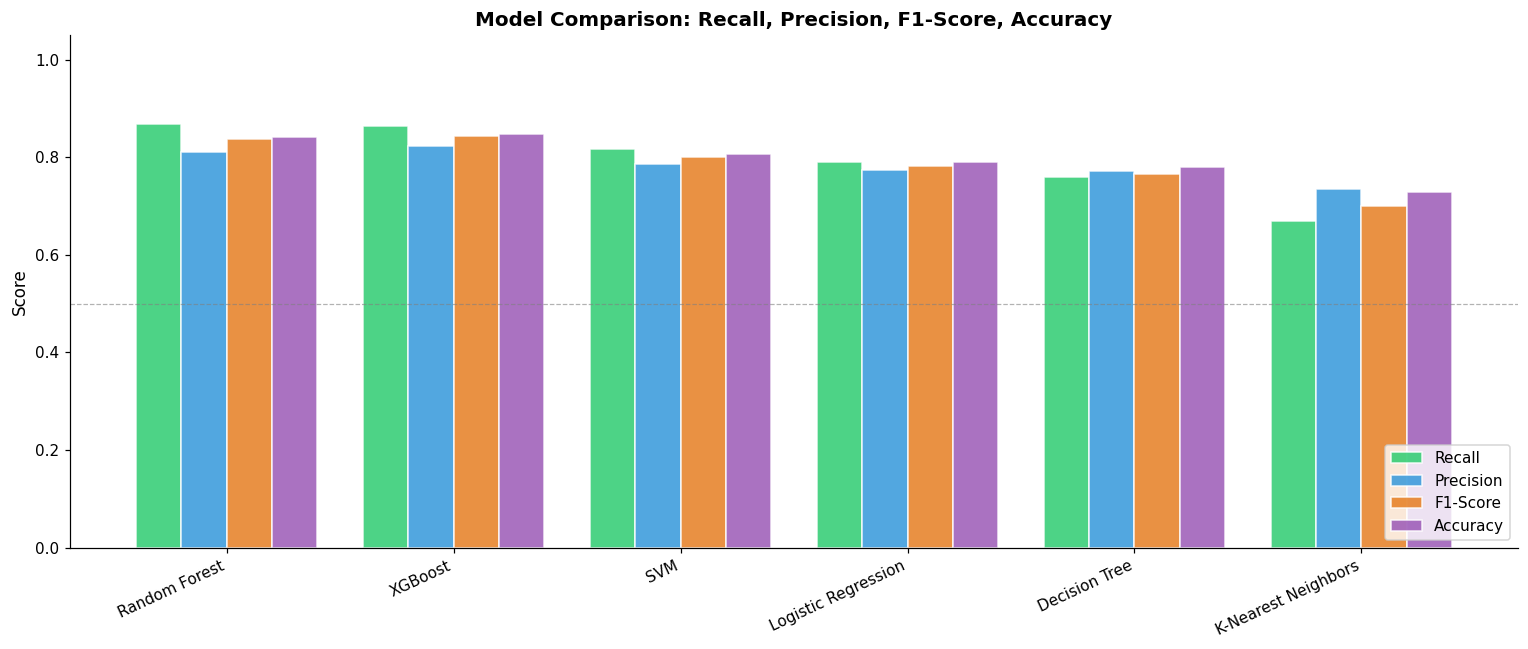

In [16]:
# Visual comparison bar chart 
metrics_to_plot = ["Recall", "Precision", "F1-Score", "Accuracy"]
n_metrics = len(metrics_to_plot)
x = np.arange(len(results_df))
bar_width = 0.20

fig, ax = plt.subplots(figsize=(14, 6))
bar_colors = ["#2ecc71", "#3498db", "#e67e22", "#9b59b6"]

for i, (metric, color) in enumerate(zip(metrics_to_plot, bar_colors)):
    bars = ax.bar(x + i * bar_width, results_df[metric], bar_width,
                  label=metric, color=color, alpha=0.85, edgecolor="white")

ax.set_xticks(x + bar_width * 1.5)
ax.set_xticklabels(results_df["Model"], rotation=25, ha="right", fontsize=10)
ax.set_ylabel("Score", fontsize=11)
ax.set_title("Model Comparison: Recall, Precision, F1-Score, Accuracy", fontsize=13, fontweight="bold")
ax.legend(fontsize=10, loc="lower right")
ax.set_ylim(0, 1.05)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()


## 9. Best Model — Random Forest


In [17]:
# Identify & retrain the best model 
best_name = results_df.iloc[0]["Model"]
best_clf  = dict(classifiers)[best_name]

print(f"Best model: {best_name}")
print("Fitting on full training set and evaluating on test set\n")

# Fit with SMOTE on train, predict on untouched test set
smote_final  = SMOTE(random_state=SEED)
X_res, y_res = smote_final.fit_resample(X_train_scaled, y_train)
best_clf.fit(X_res, y_res)

y_pred      = best_clf.predict(X_test_scaled)
y_pred_prob = best_clf.predict_proba(X_test_scaled)[:, 1] if hasattr(best_clf, "predict_proba") else None

print(f"Accuracy  : {accuracy_score(y_test, y_pred):.3f}")
print(f"Recall    : {recall_score(y_test, y_pred):.3f} ")
print(f"Precision : {precision_score(y_test, y_pred):.3f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.3f}")


Best model: Random Forest
Fitting on full training set and evaluating on test set

Accuracy  : 0.849
Recall    : 0.877 
Precision : 0.817
F1-Score  : 0.846


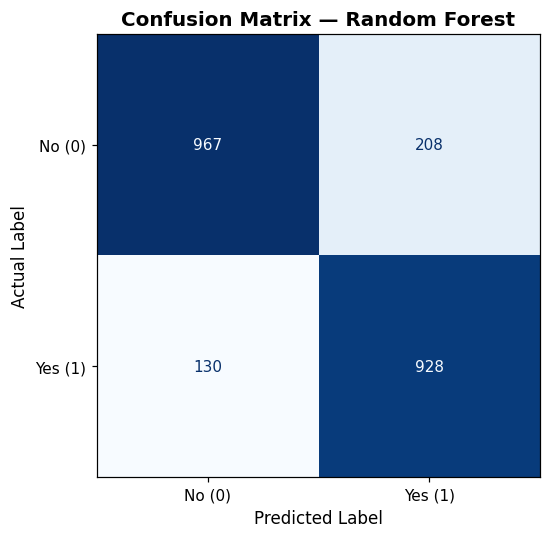


Confusion Matrix Breakdown:
  True Positives  (TP):  928  — correctly predicted 'Yes' 
  True Negatives  (TN):  967  — correctly predicted 'No' 
  False Positives (FP):  208  — predicted 'Yes' but actually 'No' (wasted calls)
  False Negatives (FN):  130  — predicted 'No'  but actually 'Yes' (missed subscribers)


In [18]:
# Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No (0)", "Yes (1)"])
disp.plot(ax=ax, colorbar=False, cmap="Blues")

ax.set_title(f"Confusion Matrix — {best_name}", fontsize=13, fontweight="bold")
ax.set_xlabel("Predicted Label", fontsize=11)
ax.set_ylabel("Actual Label", fontsize=11)

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion Matrix Breakdown:")
print(f"  True Positives  (TP): {tp:>4}  — correctly predicted 'Yes' ")
print(f"  True Negatives  (TN): {tn:>4}  — correctly predicted 'No' ")
print(f"  False Positives (FP): {fp:>4}  — predicted 'Yes' but actually 'No' (wasted calls)")
print(f"  False Negatives (FN): {fn:>4}  — predicted 'No'  but actually 'Yes' (missed subscribers)")


In [19]:
# Full classification report 
print("=" * 50)
print(f"CLASSIFICATION REPORT — {best_name}")
print("=" * 50)
print(classification_report(y_test, y_pred, target_names=["No", "Yes"]))


CLASSIFICATION REPORT — Random Forest
              precision    recall  f1-score   support

          No       0.88      0.82      0.85      1175
         Yes       0.82      0.88      0.85      1058

    accuracy                           0.85      2233
   macro avg       0.85      0.85      0.85      2233
weighted avg       0.85      0.85      0.85      2233



## 10. Feature Importance 

Understanding **which features drive predictions** helps the business focus on the right client characteristics.


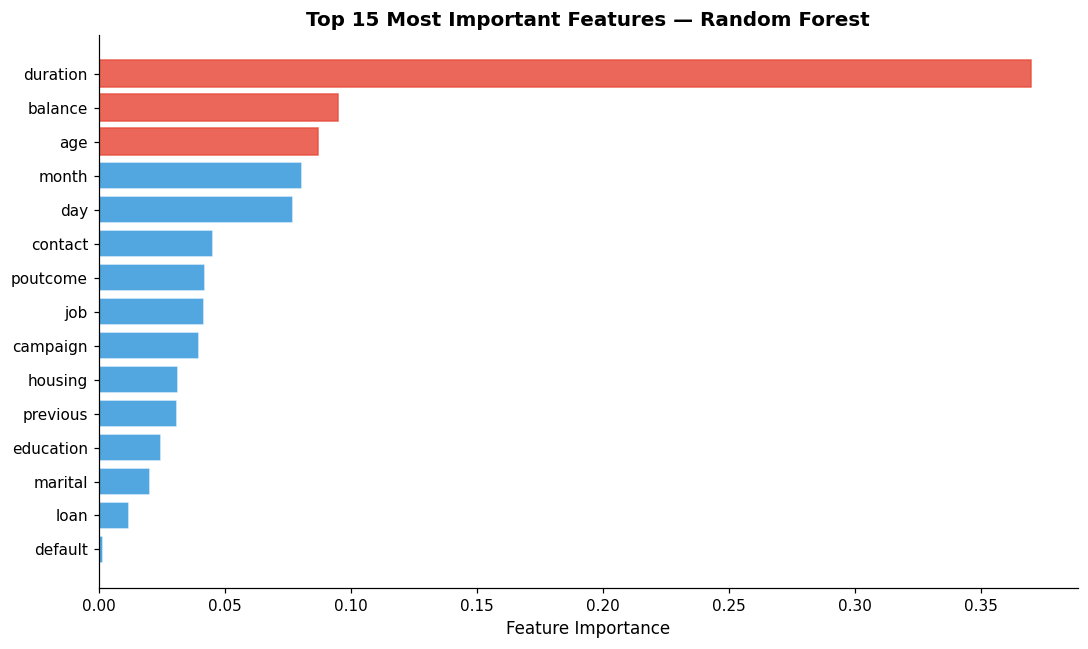

Red bars = top 3 most influential features

Top 5 most important features:
  duration                                 0.3700
  balance                                  0.0951
  age                                      0.0872
  month                                    0.0806
  day                                      0.0772


In [20]:
# Feature importance (works for tree-based models & logistic regression | rq : (SVM / KNN do not expose feature importances)) 
feature_names = list(X_raw.columns)

importance_vals = None

if hasattr(best_clf, "feature_importances_"):
    # Tree-based models (Random Forest, XGBoost, Decision Tree)
    importance_vals = best_clf.feature_importances_
    importance_label = "Feature Importance"
elif hasattr(best_clf, "coef_"):
    # Linear models (Logistic Regression)
    importance_vals = np.abs(best_clf.coef_[0])
    importance_label = "Absolute Coefficient"

if importance_vals is not None:
    feat_imp = pd.DataFrame({
        "Feature":    feature_names,
        "Importance": importance_vals
    }).sort_values("Importance", ascending=False).head(15)

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(feat_imp["Feature"][::-1], feat_imp["Importance"][::-1],
                   color=PALETTE["main"], alpha=0.85, edgecolor="white")

    # Colour the top 3 differently
    for i, bar in enumerate(bars[-3:]):
        bar.set_color("#e74c3c")

    ax.set_xlabel(importance_label, fontsize=11)
    ax.set_title(f"Top 15 Most Important Features — {best_name}",
                 fontsize=13, fontweight="bold")
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

    print("Red bars = top 3 most influential features")
    print("\nTop 5 most important features:")
    for _, row in feat_imp.head(5).iterrows():
        print(f"  {row['Feature']:<40} {row['Importance']:.4f}")
else:
    print(f"Feature importance not directly available for {best_name}.")
    print("   (SVM / KNN do not expose feature importances)")


## 11. ROC Curve Comparison



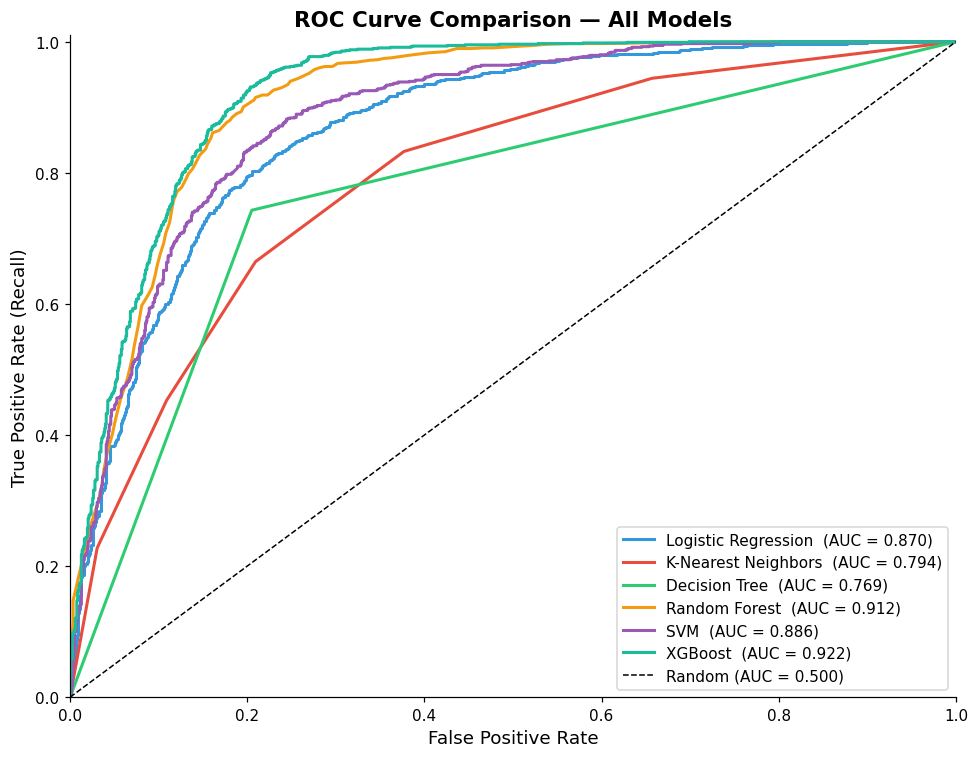

The model with the highest AUC has the best overall discrimination ability.


In [21]:
# ROC curves for all models 
roc_colors = ["#3498db","#e74c3c","#2ecc71","#f39c12","#9b59b6","#1abc9c"]

fig, ax = plt.subplots(figsize=(9, 7))

for (name, clf), color in zip(classifiers, roc_colors):
    # Re-fit each model on SMOTE-resampled train data
    smote_tmp = SMOTE(random_state=SEED)
    X_r, y_r  = smote_tmp.fit_resample(X_train_scaled, y_train)
    clf.fit(X_r, y_r)

    if hasattr(clf, "predict_proba"):
        probs = clf.predict_proba(X_test_scaled)[:, 1]
    else:
        probs = clf.decision_function(X_test_scaled)

    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc     = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=2,
            label=f"{name}  (AUC = {roc_auc:.3f})")

# Reference line (random classifier)
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random (AUC = 0.500)")

ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate (Recall)", fontsize=12)
ax.set_title("ROC Curve Comparison — All Models", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", fontsize=10)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.01])
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

print("The model with the highest AUC has the best overall discrimination ability.")


## 12. Threshold Discussion

By default, models classify a client as "Yes" if the predicted probability ≥ **0.5**.
Lowering this threshold catches **more subscribers** (higher Recall) but also calls **more non-subscribers** (lower Precision).


In [22]:
# Precision / Recall trade-off at different thresholds
if y_pred_prob is not None:
    thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

    rows = []
    for t in thresholds:
        y_pred_t = (y_pred_prob >= t).astype(int)
        rows.append({
            "Threshold": t,
            "Recall":    recall_score(y_test, y_pred_t),
            "Precision": precision_score(y_test, y_pred_t, zero_division=0),
            "F1-Score":  f1_score(y_test, y_pred_t, zero_division=0),
        })

    thresh_df = pd.DataFrame(rows)

    print("Threshold Analysis:")
    display(thresh_df.style.format({
        "Threshold": "{:.1f}",
        "Recall":    "{:.3f}",
        "Precision": "{:.3f}",
        "F1-Score":  "{:.3f}",
    }).background_gradient(subset=["F1-Score"], cmap="Greens"))

    print("\nA lower threshold (e.g. 0.3–0.4) catches more subscribers")
    print("but also generates more unnecessary calls — choose based on campaign budget.")
else:
    print(f"Threshold analysis requires probability scores — not available for {best_name}.")


Threshold Analysis:


,Threshold,Recall,Precision,F1-Score
0,0.3,0.960,0.754,0.845
1,0.4,0.919,0.788,0.848
2,0.5,0.880,0.815,0.846
3,0.6,0.805,0.840,0.822
4,0.7,0.678,0.857,0.757



A lower threshold (e.g. 0.3–0.4) catches more subscribers
but also generates more unnecessary calls — choose based on campaign budget.


## 13. Business Interpretation of Results

### 🏦 What does this mean for the bank?


In [23]:
# Business impact summary 
total_actual_yes = int(y_test.sum())
total_predicted_yes = int(y_pred.sum())
tp_count = int((y_pred * y_test).sum())

pct_caught = tp_count / total_actual_yes * 100
wasted_calls_pct = (total_predicted_yes - tp_count) / total_predicted_yes * 100 if total_predicted_yes > 0 else 0

print("=" * 60)
print("BUSINESS IMPACT SUMMARY")
print("=" * 60)
print(f"  Test set size            : {len(y_test)} clients")
print(f"  Actual subscribers (Yes) : {total_actual_yes}")
print(f"  Clients flagged by model : {total_predicted_yes}")
print(f"  True subscribers caught  : {tp_count}  ({pct_caught:.1f}% of all real subscribers)")
print(f"  Calls 'wasted' on No's   : {total_predicted_yes - tp_count}  ({wasted_calls_pct:.1f}% of all flagged calls)")
print()
print("📌 Interpretation:")
print(f"  Our random forest model correctly identifies {pct_caught:.0f}% of clients")
print(f"  who would actually subscribe — these are the people worth calling.")
print(f"  About {wasted_calls_pct:.0f}% of calls flagged by the model go to non-subscribers,")
print(f"  which is an acceptable trade-off in most marketing contexts.")
print()
print("✅ Using this model, the bank can:")
print("  • Focus call-centre resources on the highest-probability clients")
print("  • Reduce wasted outreach compared to calling everyone")
print("  • Increase overall campaign efficiency and conversion rate")


BUSINESS IMPACT SUMMARY
  Test set size            : 2233 clients
  Actual subscribers (Yes) : 1058
  Clients flagged by model : 1136
  True subscribers caught  : 928  (87.7% of all real subscribers)
  Calls 'wasted' on No's   : 208  (18.3% of all flagged calls)

📌 Interpretation:
  Our random forest model correctly identifies 88% of clients
  who would actually subscribe — these are the people worth calling.
  About 18% of calls flagged by the model go to non-subscribers,
  which is an acceptable trade-off in most marketing contexts.

✅ Using this model, the bank can:
  • Focus call-centre resources on the highest-probability clients
  • Reduce wasted outreach compared to calling everyone
  • Increase overall campaign efficiency and conversion rate
